# Coding Assignment 0: Environment Check — Local Jupyter

---

## 🎯 Purpose

This notebook does not teach you anything. It confirms that Python, NumPy, matplotlib, Jupyter, and the course portal all work on **your machine** before any of that matters for a grade.

Do this in Week 1. Not in Week 2, the night Coding Assignment 1 is due.

Setup problems are ordinary and fixable, but they are only fixable if there is time. There is no late work in this course.

## ⏱ Estimated Time: 15 minutes, if nothing is wrong

## 📦 What to Submit

Run every cell in order (**Kernel → Restart & Run All**), then Save the completed `.ipynb` after **Kernel → Restart & Run All**.

If you cannot get the report to pass after an honest attempt, **submit the notebook anyway, with the failures in it**, and email me. Silence is what I cannot help with.

---


## Check 1: Python itself

You need Python 3.10 or newer. If this cell reports an older version, install a current Python (or a current Anaconda distribution) before going further — several things later in the course will fail in confusing ways on an old interpreter.


In [1]:
import sys, platform

report = {}

version = sys.version_info
ok = (version.major, version.minor) >= (3, 10)
report["python"] = ok

print(f"Python executable : {sys.executable}")
print(f"Python version    : {version.major}.{version.minor}.{version.micro}")
print(f"Platform          : {platform.platform()}")
print()
print("PASS — Python 3.10+" if ok else
      f"FAIL — you have Python {version.major}.{version.minor}; this course needs 3.10 or newer.")


Python executable : /usr/bin/python3
Python version    : 3.12.3
Platform          : Linux-6.12.113+-x86_64-with-glibc2.39

PASS — Python 3.10+


## Check 2: The libraries

We use NumPy for essentially everything and matplotlib for plots. A few later assignments use SciPy and scikit-learn.

If any of these are missing, install them from a terminal with:

```
pip install numpy matplotlib scipy scikit-learn
```

(Anaconda users: `conda install numpy matplotlib scipy scikit-learn`.)


In [2]:
required = ["numpy", "matplotlib"]
optional = ["scipy", "sklearn"]

import importlib

missing_required, missing_optional = [], []

for name in required + optional:
    try:
        mod = importlib.import_module(name)
        v = getattr(mod, "__version__", "unknown")
        print(f"  {name:12s} {v}")
    except ImportError:
        print(f"  {name:12s} NOT FOUND")
        (missing_required if name in required else missing_optional).append(name)

report["libraries"] = not missing_required
print()
if missing_required:
    print(f"FAIL — install these before continuing: {' '.join(missing_required)}")
elif missing_optional:
    print(f"PASS — but install these before Week 9: {' '.join(missing_optional)}")
else:
    print("PASS — all libraries present")


  numpy        2.5.5
  matplotlib   3.11.2
  scipy        1.18.1


  sklearn      1.9.1

PASS — all libraries present


## Check 3: NumPy actually computes

This is not a test of your linear algebra. It is a test of whether your NumPy installation is linked against a working linear algebra backend. A NumPy that imports but cannot factor a matrix is a real failure mode, and it is better to see it here than in Week 4.


In [3]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)

checks = []

# Solve a linear system
A = np.array([[4., 1., 0.],
              [1., 3., 1.],
              [0., 1., 2.]])
b = np.array([1., 2., 3.])
x = np.linalg.solve(A, b)
checks.append(("solve",  np.allclose(A @ x, b)))

# Symmetric eigendecomposition
evals, evecs = np.linalg.eigh(A)
checks.append(("eigh",   np.allclose(A @ evecs, evecs * evals)))

# SVD
U, s, Vt = np.linalg.svd(np.arange(12.).reshape(3, 4))
checks.append(("svd",    np.allclose(U @ np.diag(s) @ Vt[:3], np.arange(12.).reshape(3, 4))))

# QR
Q, R = np.linalg.qr(A)
checks.append(("qr",     np.allclose(Q @ R, A) and np.allclose(Q.T @ Q, np.eye(3))))

for name, passed in checks:
    print(f"  {name:8s} {'ok' if passed else 'FAILED'}")

report["numpy_math"] = all(p for _, p in checks)
print()
print("PASS — NumPy linear algebra works" if report["numpy_math"] else
      "FAIL — NumPy imported but computed wrong answers. Reinstall NumPy; if that does not fix it, email me.")


  solve    ok
  eigh     ok
  svd      ok
  qr       ok

PASS — NumPy linear algebra works


## Check 4: Plots render

Several assignments ask you to produce a plot. This cell should display a small figure below it. If you see nothing, or only a line of text like `<Figure size ...>`, your matplotlib backend is misconfigured.


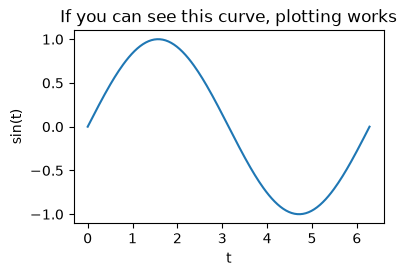

PASS — if a sine curve appeared above.


In [4]:
import matplotlib
import matplotlib.pyplot as plt

try:
    fig, ax = plt.subplots(figsize=(4, 2.5))
    t = np.linspace(0, 2*np.pi, 200)
    ax.plot(t, np.sin(t))
    ax.set_xlabel("t")
    ax.set_ylabel("sin(t)")
    ax.set_title("If you can see this curve, plotting works")
    plt.show()
    report["plotting"] = True
    print("PASS — if a sine curve appeared above.")
except Exception as e:
    report["plotting"] = False
    print(f"FAIL — {type(e).__name__}: {e}")


## Check 5: Course utilities

The coding assignments import a small helper module, `mt_utils.py`, which is distributed with each notebook.
It must sit **in the same folder as this notebook**.

The most common cause of a failure here is having the notebook and `mt_utils.py` in different folders —
for instance, the notebook in `Downloads` and the helper in a `412` folder. Put them together and re-run this cell.

```
your-folder/
  CodingHW_00_Environment_Check_Local.ipynb
  mt_utils.py          ← must be here
```


In [5]:
import os, sys
sys.path.insert(0, ".")

report["mt_utils"] = False
try:
    import mt_utils
    print(f"Found mt_utils at: {os.path.abspath(mt_utils.__file__)}")
    expected = ["set_seed", "make_embedding_matrix", "embed_tokens"]
    found = [f for f in expected if hasattr(mt_utils, f)]
    for f in expected:
        print(f"  {f:24s} {'ok' if f in found else 'missing'}")
    report["mt_utils"] = len(found) > 0
    print()
    print("PASS — course utilities importable" if report["mt_utils"] else
          "FAIL — mt_utils imported but looks wrong. Re-download it from D2L.")
except ImportError:
    print("FAIL — could not import mt_utils.")
    print()
    print("Files in this notebook's folder:")
    for f in sorted(os.listdir("."))[:25]:
        print("   ", f)
    print()
    print("If mt_utils.py is not in that list, move it here and re-run.")


Found mt_utils at: /agent/repos/Applied-AI-ML-projects/coursework/MATH412/notebooks/mt_utils.py
  set_seed                 ok
  make_embedding_matrix    ok
  embed_tokens             missing

PASS — course utilities importable


## Check 6: Portfolio seed

For course submissions, notebooks were often seeded with a personal student ID so printed samples were unique. In this published portfolio copy, use a fixed **portfolio seed** instead so results stay reproducible without personal identifiers.

Set `STUDENT_ID` in the next cell to an 8-digit portfolio seed, then run the cell twice — you should get identical output both times.


In [6]:
# Portfolio reproducibility seed (personal course ID removed for publication)
STUDENT_ID = 41202026

report["student_id"] = (STUDENT_ID != 0 and 10_000_000 <= STUDENT_ID <= 99_999_999)

if not report["student_id"]:
    print("FAIL — set STUDENT_ID to a nonzero 8-digit portfolio seed above, then re-run.")
else:
    rng = np.random.default_rng(STUDENT_ID)
    sample = rng.standard_normal(4)
    print(f"Portfolio seed: {STUDENT_ID}")
    print(f"Your sample  : {sample.round(4)}")
    print()
    print("PASS — run this cell once more. The four numbers must be identical.")


Portfolio seed: 41202026
Your sample  : [-0.63   -1.1971 -2.3307 -0.1305]

PASS — run this cell once more. The four numbers must be identical.


## Check 7: The report

Run this last. Copy nothing — just make sure it says `ALL CHECKS PASSED`, then save the notebook and upload it to the course portal.


In [7]:
labels = {
    "python":     "Python 3.10+",
    "libraries":  "Required libraries",
    "numpy_math": "NumPy linear algebra",
    "plotting":   "Matplotlib rendering",
    "mt_utils":   "Course utilities",
    "student_id": "Portfolio seed",
}

print("=" * 46)
print("  ENVIRONMENT CHECK")
print("=" * 46)

for key, label in labels.items():
    status = report.get(key)
    mark = "PASS" if status else ("FAIL" if status is False else "NOT RUN")
    print(f"  {label:24s} {mark}")

print("=" * 46)

if all(report.get(k) for k in labels):
    print("  ALL CHECKS PASSED")
    print("  Save this notebook after Kernel → Restart & Run All.")
else:
    failed = [labels[k] for k in labels if not report.get(k)]
    print("  NOT READY —", ", ".join(failed))
    print()
    print("  Fix what you can, then re-run: Kernel > Restart & Run All.")
    print("  If you are stuck after an honest attempt, fix what you can")
    print("  and re-run Kernel → Restart & Run All.")
print("=" * 46)


  ENVIRONMENT CHECK
  Python 3.10+             PASS
  Required libraries       PASS
  NumPy linear algebra     PASS
  Matplotlib rendering     PASS
  Course utilities         PASS
  Portfolio seed           PASS
  ALL CHECKS PASSED
  Save this notebook after Kernel → Restart & Run All.
